In [12]:
import image_processing
import slda
import numpy as np
import torch
from tqdm import tqdm, trange
np.random.seed(512)

In [2]:
data_dir = '../../test_data/MSRC_v2/Images/cows/'
image_files = image_processing.get_image_paths(data_dir)
np.random.shuffle(image_files)
#c, all_words, all_shapes = image_processing.assemble_visual_word_data(image_files)

In [10]:
np.save('../../test_data/MSRC_v2/cows_featurized_msrc_shuffled.npy', all_words)
np.save('../../test_data/MSRC_v2/cows_all_shapes_msrc_shuffled.npy', all_shapes)
np.save('../../test_data/MSRC_v2/cows_c_msrc_shuffled.npy', c)

In [3]:
all_words = np.load('../../test_data/MSRC_v2/cows_featurized_msrc_shuffled.npy')
all_shapes = np.load('../../test_data/MSRC_v2/cows_all_shapes_msrc_shuffled.npy')
c = np.load('../../test_data/MSRC_v2/cows_c_msrc_shuffled.npy')

In [10]:
all_words = all_words[:1500000]
#all_shapes = all_shapes[:200]
c = c[:1500000]

In [4]:
vocab_size = 200
n_topics = 15
sigma = 30
n_docs = 9
n_imgs = all_shapes.shape[0]

alpha = torch.ones((n_topics,))/n_topics
beta = torch.ones(vocab_size)/vocab_size

assignments, kmeans = image_processing.cluster_descriptors(all_words, vocab_size)

In [22]:
n_imgs

30

In [5]:
input_arr = slda.build_input_word_array(assignments, c)
z, docs, n_dk, n_kw, n_d, n_k = slda.initialize_model(input_arr, n_imgs, n_docs, n_topics, vocab_size)

In [6]:
document_locs, docs_in_img = slda.initialize_documents(all_shapes, n_docs, n_imgs)

In [7]:
pi_hat, phi_hat, n_dk, n_kw, n_k, n_d, docs, z = slda.train_model(input_arr, document_locs, docs_in_img, n_imgs, n_docs, n_topics, vocab_size, z, docs, n_dk, n_kw, n_d, n_k, alpha, beta, sigma, n_epochs=10)

  0%|          | 0/222600 [00:00<?, ?it/s]/Users/ethan/Dropbox (MIT)/Lab/lda_implementations/slda/code/slda.py:174: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  kernel_arg = torch.tensor(-1.0*((x_d-x_i)**2.0 + (y_d-y_i)**2)/sigma**2., dtype=float)
100%|██████████| 222600/222600 [02:27<00:00, 1510.46it/s]
9 tensor(167.7697)


In [9]:
best_topics = torch.zeros((phi_hat.shape[1], pi_hat.shape[0], phi_hat.shape[0]))

for w in range(phi_hat.shape[1]):
    for d in range(pi_hat.shape[0]):
        best_topics[w][d] = pi_hat[d]*phi_hat[:, w]

In [13]:
best_topic = torch.zeros((len(c),))
x_i_new, y_i_new, all_gx, all_gy = slda.make_vectorizable_vars(document_locs, input_arr, n_docs)

for i in trange(0, best_topic.shape[0]):
    g = int(c[i, 0])
    x = c[i, 1]
    y = c[i, 2]
    word = assignments[i]
    start = g * n_docs
    end = (g+1) * n_docs
    p = best_topics[word, start:end, :].T @ torch.exp(-((x-document_locs[start:end, 1])**2 + (y-document_locs[start:end, 2])**2)/sigma**2)
    best_topic[i] = p.argmax()

100%|██████████| 222600/222600 [00:27<00:00, 8199.34it/s]


In [14]:
start = g * n_docs
end = (g+1) * n_docs

from skimage import color, io
import matplotlib.pyplot as plt

idx = 25
outpath = '../../test_data/MSRC_v2/Images/cows/seg_results/'

def segment_images(outpath, idx, image_files=image_files, save = True):
    
    original_img = image_processing.load_image(image_files, idx)
    shape = (original_img.shape[0], original_img.shape[1])
    new_img = np.ones(shape) * -1
    visual_words, coords = image_processing.make_visual_words(original_img)
    coords = np.array(coords)
    img_topic_labels = np.array(best_topic[idx*visual_words.shape[0]:(idx + 1)*visual_words.shape[0]])

    for i in range(0, visual_words.shape[0]):
        new_img[int(coords[i,0])-1:int(coords[i, 0])+2, int(coords[i,1])-1:int(coords[i,1])+2] = (np.ones(9)*img_topic_labels[i]).reshape(3, 3)
    
    if save:
        plt.clf()
        io.imshow(color.label2rgb(new_img, bg_label = -1))
        name = image_files[idx].split('/')[-1].split('.')[0]
        plt.savefig(outpath + name + '_segmented' + '.pdf')
    else:
        return new_img

In [19]:
new_img = segment_images(None, 10, image_files=image_files, save=False)

ipykernel_launcher:1: FutureWarning: The new recommended value for bg_label is 0. Until version 0.19, the default bg_label value is -1. From version 0.19, the bg_label default value will be 0. To avoid this warning, please explicitly set bg_label value.


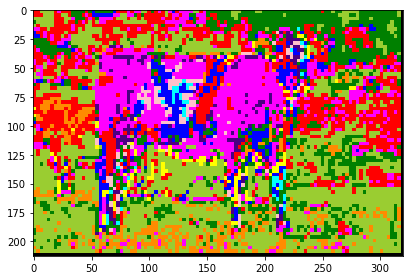

In [20]:
io.imshow(color.label2rgb(new_img))